## Introducción

El presente proyecto tiene como objetivo analizar los datos de una campaña de marketing bancario para identificar el comportamiento de los clientes y los factores que influyen en la contratación de un depósito a plazo. 

A través de la exploración, limpieza y análisis de los datos, se busca obtener información relevante que permita identificar patrones y generar conclusiones que contribuyan a mejorar la toma de decisiones y la efectividad de futuras campañas comerciales.

### Inicio

In [1]:
#solo es para ver si esta tomando mi ambiente
import sys
print(sys.executable)

c:\proye_shada\MarketingBancario\.venv\Scripts\python.exe


In [2]:
# Cargar todas las librerías
import pandas as pd
import os       #para ver si logro llegar al archivo con la ruta de datos
import matplotlib.pyplot as plt

In [3]:
print("Carpeta actual:", os.getcwd())
print("Contenido de la carpeta:", os.listdir())

#C:\proye_shada\MarketingBancario\data\bank-full.xlsx
#df_retail = pd.read_excel('data/bank-full.xlsx')---------Esta ruta es para python
df_banco = pd.read_csv('../data/bank-full.csv',sep=';')

Carpeta actual: c:\proye_shada\MarketingBancario\notebooks
Contenido de la carpeta: ['exploracion.ipynb', 'marketing.ipynb']


In [4]:
# Muestra los nombres de las columnas

print(df_banco.columns)

Index(['age', 'job', 'marital', 'education', 'default', 'balance', 'housing',
       'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'y'],
      dtype='str')


In [5]:
'''
#se procede a cambiar los nombres de las columnas por unas mas claras
#cambio de nombres de las columnas

nuevos_nombres = {
    'InvoiceNo': 'num_factura',
    'StockCode': 'cod_articulo',
    'Description': 'descripcion',
    'Quantity': 'cantidad',
    'InvoiceDate': 'fh_factura',
    'UnitPrice': 'precio_unitario',
    'CustomerID': 'id_cliente',
    'Country': 'pais'
}

df_retail = df_retail.rename(columns=nuevos_nombres)
print('*' * 120)

print(df_retail.columns.tolist())

'''


"\n#se procede a cambiar los nombres de las columnas por unas mas claras\n#cambio de nombres de las columnas\n\nnuevos_nombres = {\n    'InvoiceNo': 'num_factura',\n    'StockCode': 'cod_articulo',\n    'Description': 'descripcion',\n    'Quantity': 'cantidad',\n    'InvoiceDate': 'fh_factura',\n    'UnitPrice': 'precio_unitario',\n    'CustomerID': 'id_cliente',\n    'Country': 'pais'\n}\n\ndf_retail = df_retail.rename(columns=nuevos_nombres)\nprint('*' * 120)\n\nprint(df_retail.columns.tolist())\n\n"

In [6]:
print(df_banco.columns.tolist())

['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']


## Extración de registros

In [7]:
print('*' * 120)
print('*' * 40 +'df_banco------- solo los 5 registros' + '*' * 40)
print(df_banco.head())
print('*' * 120)

************************************************************************************************************************
****************************************df_banco------- solo los 5 registros****************************************
   age           job  marital  education default  balance housing loan  \
0   58    management  married   tertiary      no     2143     yes   no   
1   44    technician   single  secondary      no       29     yes   no   
2   33  entrepreneur  married  secondary      no        2     yes  yes   
3   47   blue-collar  married    unknown      no     1506     yes   no   
4   33       unknown   single    unknown      no        1      no   no   

   contact  day month  duration  campaign  pdays  previous poutcome   y  
0  unknown    5   may       261         1     -1         0  unknown  no  
1  unknown    5   may       151         1     -1         0  unknown  no  
2  unknown    5   may        76         1     -1         0  unknown  no  
3  unknown    5   may

# Información de columnas

In [8]:
print('*' * 120)
print('*' * 40 +'df_banco' + '*' * 40)
#display(df_calls.head())
print('*' * 120)
print(df_banco.info())
print('*' * 120)

************************************************************************************************************************
****************************************df_banco****************************************
************************************************************************************************************************
<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 

### Nota: vaya aparentemente no tiene valores nulos, ni faltantes

In [9]:
print('*' * 120)
print('*' * 40 +'df_banco------- revisión de valores ausentes' + '*' * 40)
print(df_banco.isna().sum())
print('*' * 120)


************************************************************************************************************************
****************************************df_banco------- revisión de valores ausentes****************************************
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64
************************************************************************************************************************


Revisando antes de que algo pase, segun esto no hay valores ausentes



📌 Se observan que en este data set no se cuenta con valores, <br>
vamos a revisar si hay valores duplicados, para realizar una limpieza mas generica creo que lo mas importante es quitar duplicados,<br>
procedemos a revisar


In [10]:
#antes de hacer cambios realicemos copia y trabajemos en ella

df_banco_2 = df_banco.copy()

 📌 dentro de los registros de trabajo podemos encontrar y armar un catalogo: 

🔹 edad :  Entero  |
🔹 Tipo de trabajo: Categórico | 'administrativo', 'obrero', 'emprendedor', 'empleada doméstica', 'gestión', 'jubilado', 'autónomo', 'servicios', 'estudiante', 'técnico', 'desempleado', 'desconocido'
 
🔹 edo_civil: Categórico | 'divorciado', 'casado', 'soltero', 'desconocido'; nota: 'divorciado' significa divorciado o viudo

🔹 educacion :  'basic.4y','basic.6y','basic.9y','high.school','alfabetizado','professional.course','university.degree','unknown'

🔹 default:	binario |  ¿Tiene crédito en mora?
 
🔹 balance_cred : Entero | saldo anual promedio

🔹 alojamiento : binario |  ¿Tiene préstamo hipotecario?

🔹 prestamo :  binario | ¿Tiene préstamo personal?

🔹 contacto  : Categórico | Tipo de comunicación de contacto : 'celular', 'teléfono'

🔹 dia : Fecha | último día de contacto de la semana

🔹 mes : Fecha | Mes del último contacto del año (categórico: 'ene', 'feb', 'mar', ..., 'nov', 'dic')

🔹 duracion:  Entero | Duración del último contacto, en segundos (numérico). Nota importante: este atributo afecta significativamente al resultado (por ejemplo, si duración=0, entonces y='no'). Sin embargo, la duración se desconoce antes de realizar una llamada. Además, una vez finalizada la llamada, y es obviamente conocida. Por lo tanto, esta entrada solo debe incluirse con fines comparativos y debe descartarse si se pretende obtener un modelo predictivo realista.

🔹 campaña :  Entero | Número de contactos realizados durante esta campaña y para este cliente (numérico, incluye el último contacto)

🔹 dia_p : Entero | Número de días transcurridos desde la última vez que se contactó al cliente en una campaña anterior (numérico; -1 significa que no se contactó al cliente previamente).

🔹 anterior: Entero	 |	Número de contactos realizados antes de esta campaña y para este cliente.

🔹resul_campa : Categórico	|	Resultado de la campaña de marketing anterior (categórico: 'fracaso', 'inexistente', 'éxito')	

🔹y : Binario	|	¿El cliente ha contratado un depósito a plazo fijo?	

In [11]:
#se procede a cambiar los nombres de las columnas por unas mas claras
#cambio de nombres de las columnas

nuevos_nombres = {
    'age': 'edad',
    'job': 'trabajo',
    'marital': 'edo_civil',
    'education': 'educacion',
    'default': 'default',
    'balance': 'balance_cred',
    'housing': 'alojamiento',
    'loan': 'prestamo',
    'contact': 'contacto',
    'day': 'dia',
    'month': 'mes',
    'duration': 'duracion',
    'campaign': 'campaña',
    'pdays': 'dia_p',
    'previous': 'anterior',
    'poutcome': 'resul_campa',
    'y': 'contrato'
}

df_banco_2 = df_banco_2.rename(columns=nuevos_nombres)
print('*' * 120)

print(df_banco_2.columns.tolist())

************************************************************************************************************************
['edad', 'trabajo', 'edo_civil', 'educacion', 'default', 'balance_cred', 'alojamiento', 'prestamo', 'contacto', 'dia', 'mes', 'duracion', 'campaña', 'dia_p', 'anterior', 'resul_campa', 'contrato']


In [12]:
print('*' * 120)
print('*' * 40 +'df_banco_2------- revisión de valores ausentes' + '*' * 40)
# Contar duplicados explícitos
print(df_banco_2.duplicated().sum())

print('*' * 120)


************************************************************************************************************************
****************************************df_banco_2------- revisión de valores ausentes****************************************
0
************************************************************************************************************************


In [13]:
df_banco_2.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   edad          45211 non-null  int64
 1   trabajo       45211 non-null  str  
 2   edo_civil     45211 non-null  str  
 3   educacion     45211 non-null  str  
 4   default       45211 non-null  str  
 5   balance_cred  45211 non-null  int64
 6   alojamiento   45211 non-null  str  
 7   prestamo      45211 non-null  str  
 8   contacto      45211 non-null  str  
 9   dia           45211 non-null  int64
 10  mes           45211 non-null  str  
 11  duracion      45211 non-null  int64
 12  campaña       45211 non-null  int64
 13  dia_p         45211 non-null  int64
 14  anterior      45211 non-null  int64
 15  resul_campa   45211 non-null  str  
 16  contrato      45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB


In [14]:
print('*' * 120)
print('*' * 40 +'df_banco------- solo los 5 registros' + '*' * 40)
print(df_banco_2.head())
print('*' * 120)

************************************************************************************************************************
****************************************df_banco------- solo los 5 registros****************************************
   edad       trabajo edo_civil  educacion default  balance_cred alojamiento  \
0    58    management   married   tertiary      no          2143         yes   
1    44    technician    single  secondary      no            29         yes   
2    33  entrepreneur   married  secondary      no             2         yes   
3    47   blue-collar   married    unknown      no          1506         yes   
4    33       unknown    single    unknown      no             1          no   

  prestamo contacto  dia  mes  duracion  campaña  dia_p  anterior resul_campa  \
0       no  unknown    5  may       261        1     -1         0     unknown   
1       no  unknown    5  may       151        1     -1         0     unknown   
2      yes  unknown    5  may        7

In [15]:
columnas_categoricas = [
    'default',
    'alojamiento',
    'prestamo',
    'contacto',
    'contrato'
]

for columna in columnas_categoricas:
    print(f'\nValores de {columna}:')
    print(df_banco_2[columna].value_counts())


Valores de default:
default
no     44396
yes      815
Name: count, dtype: int64

Valores de alojamiento:
alojamiento
yes    25130
no     20081
Name: count, dtype: int64

Valores de prestamo:
prestamo
no     37967
yes     7244
Name: count, dtype: int64

Valores de contacto:
contacto
cellular     29285
unknown      13020
telephone     2906
Name: count, dtype: int64

Valores de contrato:
contrato
no     39922
yes     5289
Name: count, dtype: int64


In [16]:
columnas_categoricas = [
    'trabajo',
    'edo_civil',
    'educacion',
    'mes',
    'resul_campa'
]

for columna in columnas_categoricas:
    print(f'\nValores de {columna}:')
    print(df_banco_2[columna].value_counts())


Valores de trabajo:
trabajo
blue-collar      9732
management       9458
technician       7597
admin.           5171
services         4154
retired          2264
self-employed    1579
entrepreneur     1487
unemployed       1303
housemaid        1240
student           938
unknown           288
Name: count, dtype: int64

Valores de edo_civil:
edo_civil
married     27214
single      12790
divorced     5207
Name: count, dtype: int64

Valores de educacion:
educacion
secondary    23202
tertiary     13301
primary       6851
unknown       1857
Name: count, dtype: int64

Valores de mes:
mes
may    13766
jul     6895
aug     6247
jun     5341
nov     3970
apr     2932
feb     2649
jan     1403
oct      738
sep      579
mar      477
dec      214
Name: count, dtype: int64

Valores de resul_campa:
resul_campa
unknown    36959
failure     4901
other       1840
success     1511
Name: count, dtype: int64


In [17]:
df_banco_2.describe()

,edad,balance_cred,dia,duracion,campaña,dia_p,anterior
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


### Agrupemos

In [18]:
edades = df_banco_2.groupby('edad').size()
print(edades)

edad
18     12
19     35
20     50
21     79
22    129
     ... 
90      2
92      2
93      2
94      1
95      2
Length: 77, dtype: int64


In [19]:
clientes_mayores = df_banco_2[df_banco_2['edad'] >= 90]

print(clientes_mayores[['edad', 'trabajo', 'edo_civil', 'educacion', 'contrato']])

       edad  trabajo edo_civil  educacion contrato
31069    90  retired  divorced  secondary      yes
31233    94  retired  divorced  secondary       no
33699    95  retired  divorced    primary      yes
41663    95  retired   married  secondary       no
41934    92  retired   married    unknown      yes
42727    92  retired   married    unknown      yes
43194    90  retired  divorced    primary      yes
44262    93  retired   married    unknown      yes
44420    93  retired   married    unknown      yes


In [20]:
df_banco_2['edad'].describe()

count    45211.000000
mean        40.936210
std         10.618762
min         18.000000
25%         33.000000
50%         39.000000
75%         48.000000
max         95.000000
Name: edad, dtype: float64

In [21]:
rangos_edad = [18, 25, 35, 45, 55, 65, 100]

etiquetas = ['18-25', '26-35', '36-45', '46-55', '56-65', '66+']

df_banco_2['rango_edad'] = pd.cut(
    df_banco_2['edad'],
    bins=rangos_edad,
    labels=etiquetas,
    include_lowest=True
)

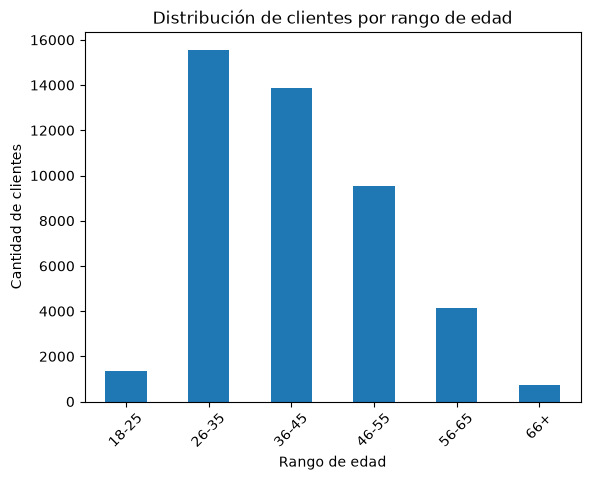

In [22]:
conteo_edades = df_banco_2['rango_edad'].value_counts().sort_index()

conteo_edades.plot(
    kind='bar',
    title='Distribución de clientes por rango de edad',
    xlabel='Rango de edad',
    ylabel='Cantidad de clientes'
)
plt.xticks(rotation=45)
plt.show()

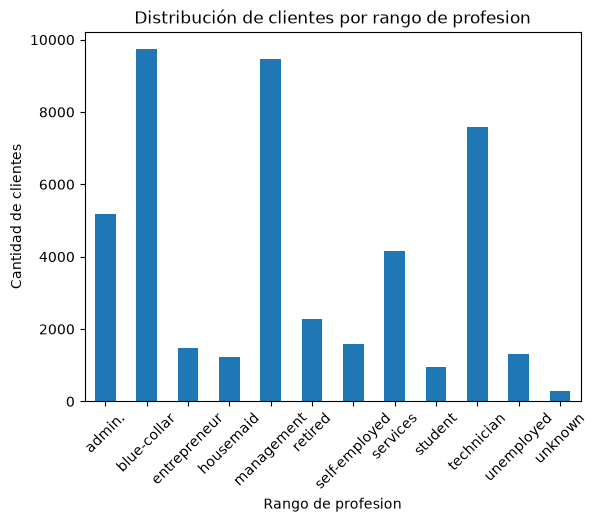

In [23]:
conteo_profesion = df_banco_2['trabajo'].value_counts().sort_index()

conteo_profesion.plot(
    kind='bar',
    title='Distribución de clientes por rango de profesion',
    xlabel='Rango de profesion',
    ylabel='Cantidad de clientes'
)
plt.xticks(rotation=45)
plt.show()

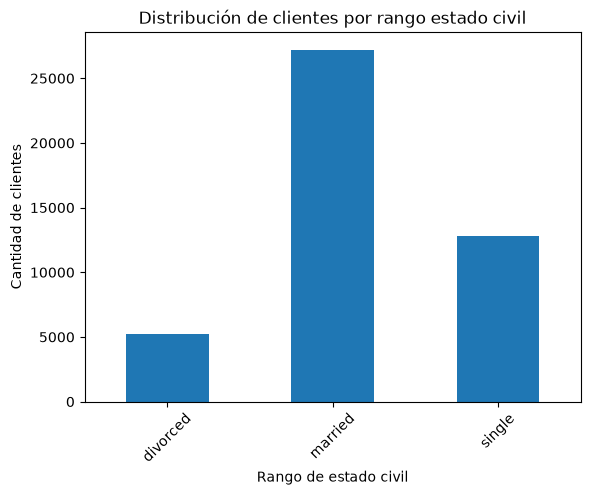

In [24]:
conteo_edo_civil = df_banco_2['edo_civil'].value_counts().sort_index()

conteo_edo_civil.plot(
    kind='bar',
    title='Distribución de clientes por rango estado civil',
    xlabel='Rango de estado civil',
    ylabel='Cantidad de clientes'
)
plt.xticks(rotation=45)
plt.show()

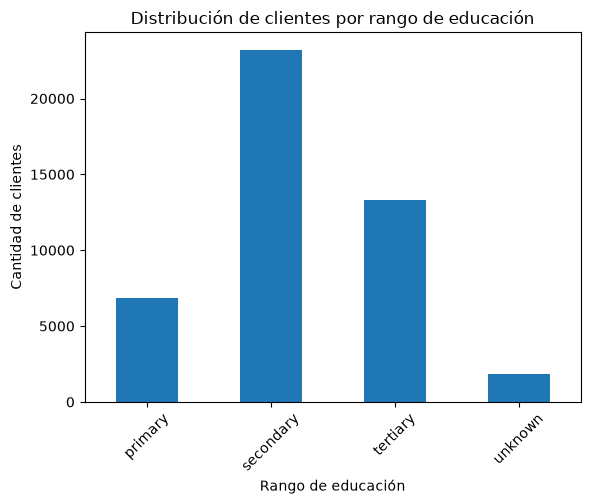

In [25]:
conteo_educa = df_banco_2['educacion'].value_counts().sort_index()

conteo_educa.plot(
    kind='bar',
    title='Distribución de clientes por rango de educación',
    xlabel='Rango de educación',
    ylabel='Cantidad de clientes'
)
plt.xticks(rotation=45)
plt.show()

In [26]:
tabla_edad = df_banco_2.groupby(
    ['rango_edad', 'contrato'],
    observed=False
).size().unstack(fill_value=0)

print(tabla_edad)

contrato       no   yes
rango_edad             
18-25        1016   320
26-35       13702  1869
36-45       12555  1301
46-55        8655   893
56-65        3563   586
66+           431   320


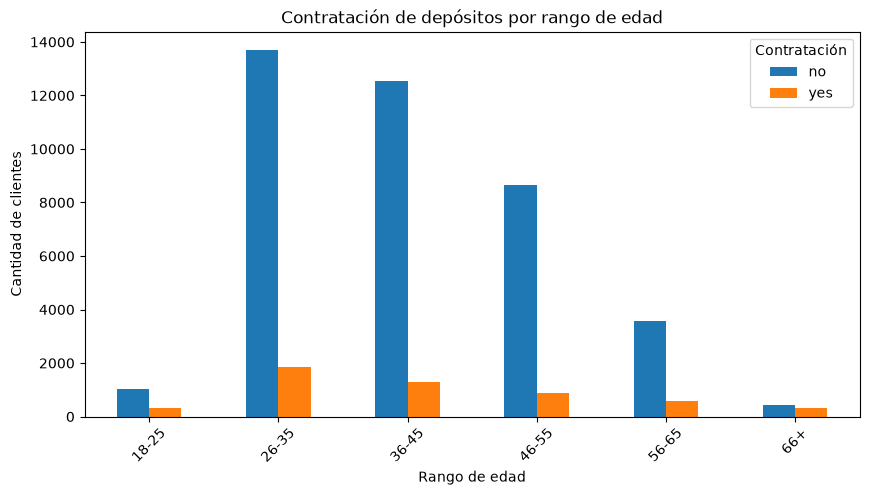

In [27]:
tabla_edad.plot(
    kind='bar',
    figsize=(10, 5),
    title='Contratación de depósitos por rango de edad',
    xlabel='Rango de edad',
    ylabel='Cantidad de clientes'
)

plt.xticks(rotation=45)
plt.legend(title='Contratación')
plt.show()

In [28]:
tabla_profes = df_banco_2.groupby(
    ['trabajo', 'contrato'],
    observed=False
).size().unstack(fill_value=0)

print(tabla_profes)

contrato         no   yes
trabajo                  
admin.         4540   631
blue-collar    9024   708
entrepreneur   1364   123
housemaid      1131   109
management     8157  1301
retired        1748   516
self-employed  1392   187
services       3785   369
student         669   269
technician     6757   840
unemployed     1101   202
unknown         254    34


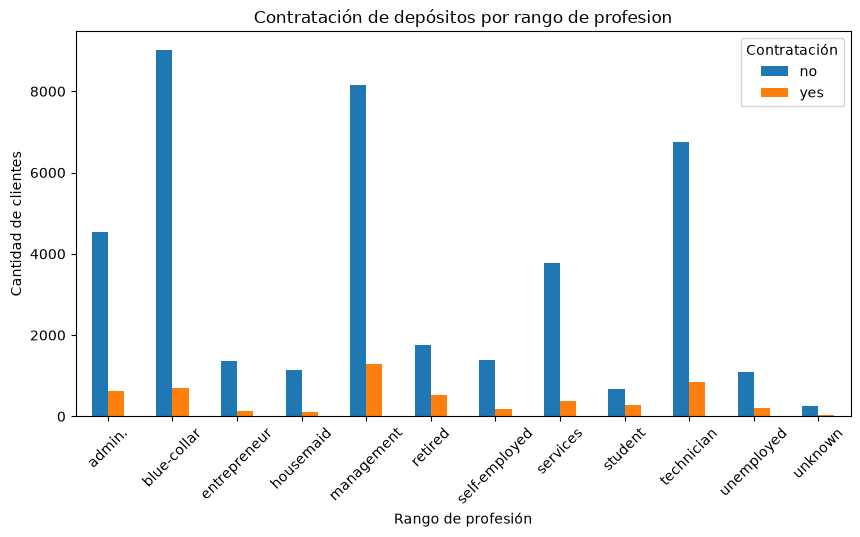

In [29]:
tabla_profes.plot(
    kind='bar',
    figsize=(10, 5),
    title='Contratación de depósitos por rango de profesion',
    xlabel='Rango de profesión',
    ylabel='Cantidad de clientes'
)

plt.xticks(rotation=45)
plt.legend(title='Contratación')
plt.show()

In [30]:
tabla_esd_civil = df_banco_2.groupby(
    ['edo_civil', 'contrato'],
    observed=False
).size().unstack(fill_value=0)

print(tabla_esd_civil)

contrato      no   yes
edo_civil             
divorced    4585   622
married    24459  2755
single     10878  1912


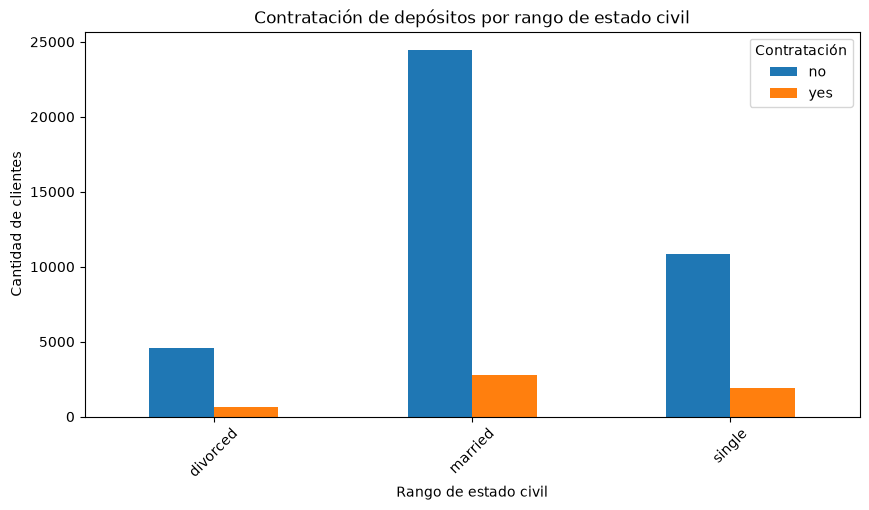

In [31]:
tabla_esd_civil.plot(
    kind='bar',
    figsize=(10, 5),
    title='Contratación de depósitos por rango de estado civil',
    xlabel='Rango de estado civil',
    ylabel='Cantidad de clientes'
)

plt.xticks(rotation=45)
plt.legend(title='Contratación')
plt.show()

In [32]:
tabla_educa = df_banco_2.groupby(
    ['educacion', 'contrato'],
    observed=False
).size().unstack(fill_value=0)

print(tabla_educa)

contrato      no   yes
educacion             
primary     6260   591
secondary  20752  2450
tertiary   11305  1996
unknown     1605   252


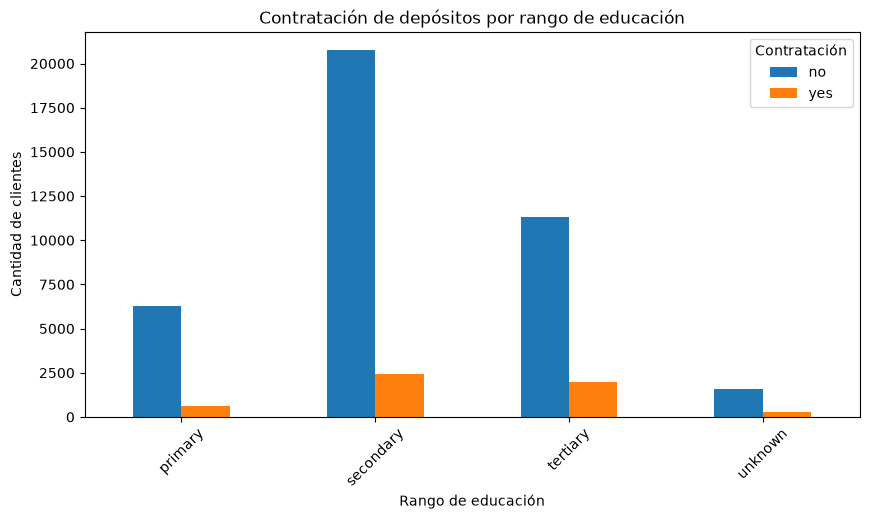

In [33]:
tabla_educa.plot(
    kind='bar',
    figsize=(10, 5),
    title='Contratación de depósitos por rango de educación',
    xlabel='Rango de educación',
    ylabel='Cantidad de clientes'
)

plt.xticks(rotation=45)
plt.legend(title='Contratación')
plt.show()

### Tasas de contratación por segmento

#### calcular la tasa por edad

In [34]:
tasa_edad = pd.crosstab(
    df_banco_2['rango_edad'],
    df_banco_2['contrato'],
    normalize='index'
) * 100

print(tasa_edad.round(2))

contrato       no    yes
rango_edad              
18-25       76.05  23.95
26-35       88.00  12.00
36-45       90.61   9.39
46-55       90.65   9.35
56-65       85.88  14.12
66+         57.39  42.61


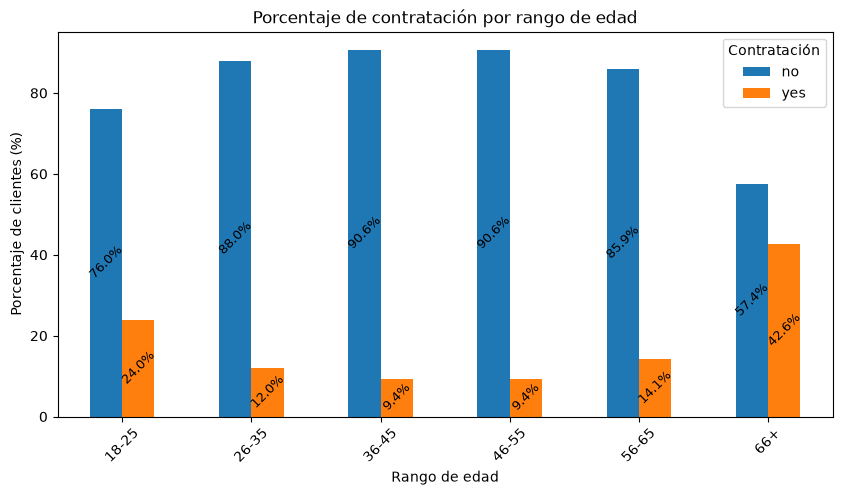

In [35]:
ax = tasa_edad.plot(
    kind='bar',
    figsize=(10, 5),
    title='Porcentaje de contratación por rango de edad',
    xlabel='Rango de edad',
    ylabel='Porcentaje de clientes (%)'
)
for contenedor in ax.containers:
    ax.bar_label(
        contenedor,
        fmt='%.1f%%',
       label_type='center',
        rotation=45,
        #color='white',
        fontsize=9

    )

plt.xticks(rotation=45)
plt.legend(title='Contratación')
plt.show()

Analizando un poco mas el rando de edad de + de 66

In [36]:
grupo_mayores = df_banco_2[df_banco_2['rango_edad'] == '66+']

print('Total de clientes:', len(grupo_mayores))
print('\nContratación:')
print(grupo_mayores['contrato'].value_counts())

print('\nSaldo bancario:')
print(grupo_mayores['balance_cred'].describe())



Total de clientes: 751

Contratación:
contrato
no     431
yes    320
Name: count, dtype: int64

Saldo bancario:
count      751.000000
mean      2822.002663
std       5594.680450
min          0.000000
25%        460.500000
50%       1413.000000
75%       3205.500000
max      81204.000000
Name: balance_cred, dtype: float64


aunque tienen una tasa de contratación elevada, representan un segmento pequeño del mercado analizado.

* Promedio: 2,822 euros.
* Mediana: 1,413 euros.
* Máximo: 81,204 euros.

¿Los clientes mayores de 66 años que contrataron tienen un saldo bancario diferente al de quienes no contrataron?

- ¿Qué rango de edad tiene más clientes?
- ¿En qué rango existe una mayor proporción de contratación?
- ¿Los clientes jóvenes contratan más que los adultos mayores?
- ¿Qué segmento podría representar una oportunidad para futuras campañas?
Vamos a hacerlo con Python.

In [37]:
# Comparar contratación por rango de edad

tabla_edades = pd.crosstab(
    df_banco_2['rango_edad'],
    df_banco_2['contrato']
)

print(tabla_edades)

contrato       no   yes
rango_edad             
18-25        1016   320
26-35       13702  1869
36-45       12555  1301
46-55        8655   893
56-65        3563   586
66+           431   320


In [38]:
# Calcular porcentajes por rango de edad

porcentaje_edades = pd.crosstab(
    df_banco_2['rango_edad'],
    df_banco_2['contrato'],
    normalize='index'
) * 100

#print(porcentaje_edades.round(2))



print(porcentaje_edades.round(2).apply(
    lambda columna: columna.map(lambda x: f'{x:.2f}%')
))

contrato        no     yes
rango_edad                
18-25       76.05%  23.95%
26-35       88.00%  12.00%
36-45       90.61%   9.39%
46-55       90.65%   9.35%
56-65       85.88%  14.12%
66+         57.39%  42.61%


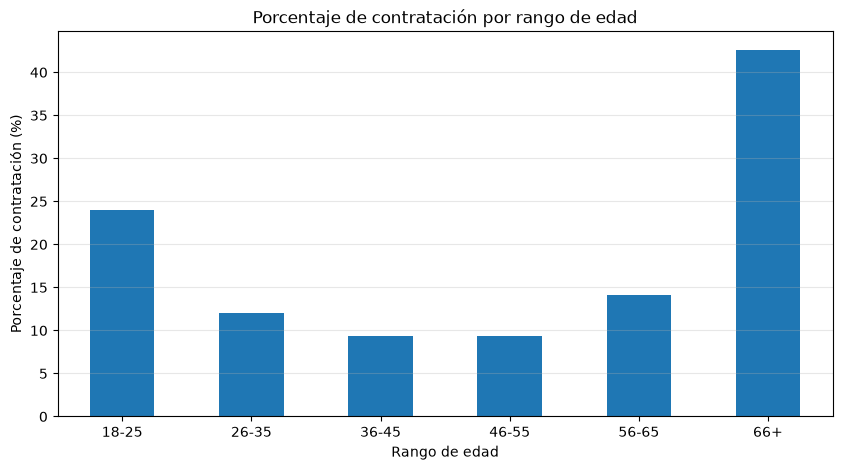

In [39]:
contratacion_edad = porcentaje_edades['yes']

plt.figure(figsize=(10, 5))
contratacion_edad.plot(kind='bar')

plt.title('Porcentaje de contratación por rango de edad')
plt.xlabel('Rango de edad')
plt.ylabel('Porcentaje de contratación (%)')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)




plt.show()

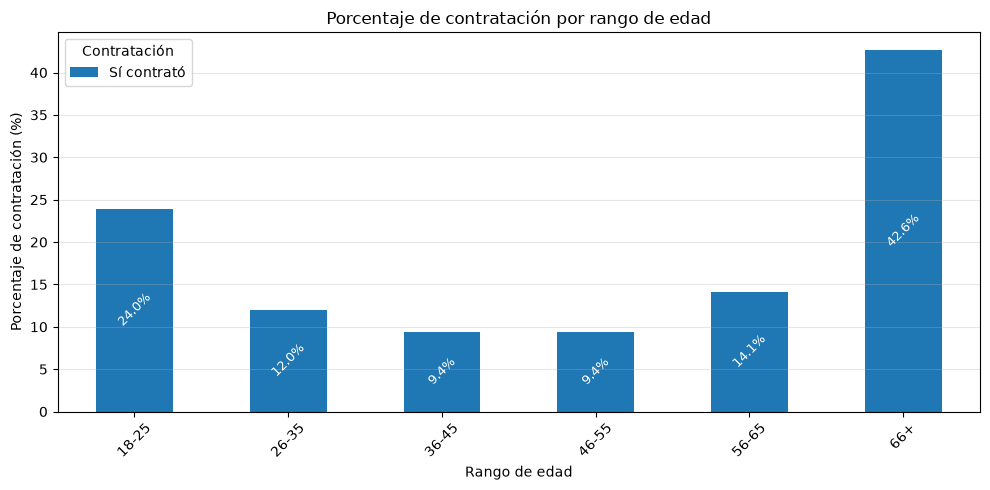

In [40]:
# Seleccionamos el porcentaje de clientes que contrataron
tasa_edad = porcentaje_edades['yes']

ax = tasa_edad.plot(
    kind='bar',
    figsize=(10, 5),
    title='Porcentaje de contratación por rango de edad',
    xlabel='Rango de edad',
    ylabel='Porcentaje de contratación (%)',
    label='Sí contrató'
)

# Agregamos las etiquetas a las barras
for contenedor in ax.containers:
    ax.bar_label(
        contenedor,
        fmt='%.1f%%',
        label_type='center',
        rotation=45,
        color='white',
        fontsize=9
    )

plt.xticks(rotation=45)
plt.legend(title='Contratación')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

#### Analizar la contratación por tipo de trabajo

In [41]:
#calcular cuántos clientes hay por ocupacion, cuántos contrataron o no, las cantidades del cliente

tabla_trabajo = pd.crosstab(
    df_banco_2['trabajo'],
    df_banco_2['contrato']
)

print(tabla_trabajo)

contrato         no   yes
trabajo                  
admin.         4540   631
blue-collar    9024   708
entrepreneur   1364   123
housemaid      1131   109
management     8157  1301
retired        1748   516
self-employed  1392   187
services       3785   369
student         669   269
technician     6757   840
unemployed     1101   202
unknown         254    34


In [42]:
#comparar porcentajes de cada ocupación
porcentaje_trabajo = pd.crosstab(
    df_banco_2['trabajo'],
    df_banco_2['contrato'],
    normalize='index'
) * 100

#print(porcentaje_trabajo.round(2))

print(porcentaje_trabajo.round(2).apply(
    lambda columna: columna.map(lambda x: f'{x:.2f}%')
))

contrato           no     yes
trabajo                      
admin.         87.80%  12.20%
blue-collar    92.73%   7.27%
entrepreneur   91.73%   8.27%
housemaid      91.21%   8.79%
management     86.24%  13.76%
retired        77.21%  22.79%
self-employed  88.16%  11.84%
services       91.12%   8.88%
student        71.32%  28.68%
technician     88.94%  11.06%
unemployed     84.50%  15.50%
unknown        88.19%  11.81%


* student: tiene el porcentaje mas alto de contratación  con 28.68 %
* retired: ocupa el segundo lugar con 22.79 %
* unemployed: contrata con un 15.81%
* blue-collar: es el mas bajo de contratos con un 7.27%

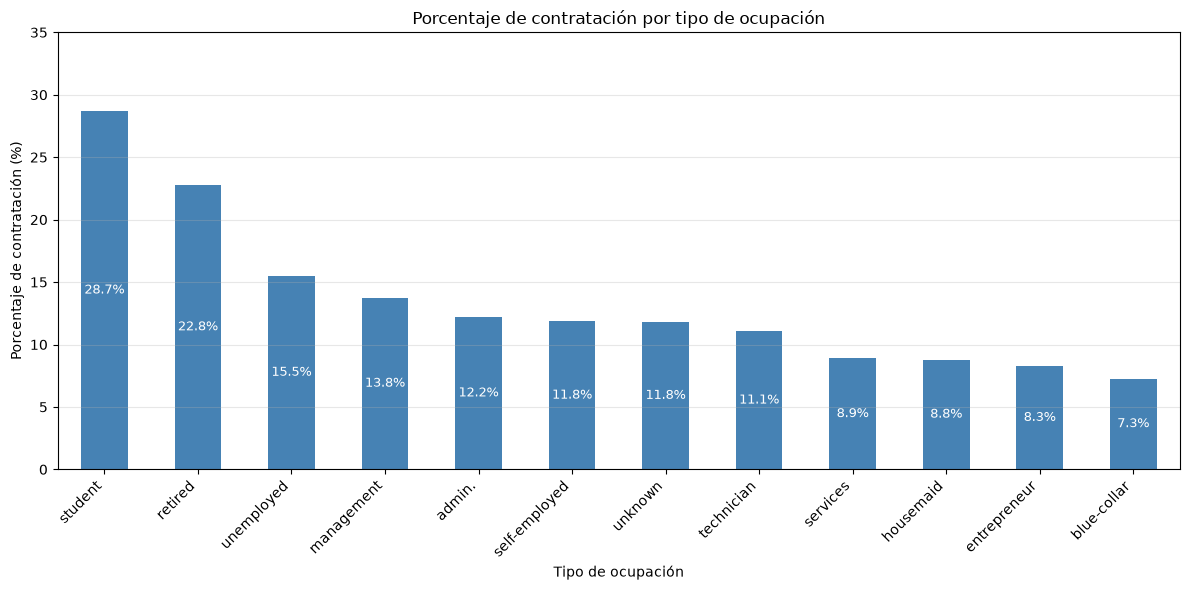

In [43]:
# Seleccionamos y ordenamos el porcentaje de contratación
tasa_trabajo = porcentaje_trabajo['yes'].sort_values(ascending=False)

ax = tasa_trabajo.plot(
    kind='bar',
    figsize=(12, 6),
    title='Porcentaje de contratación por tipo de ocupación',
    xlabel='Tipo de ocupación',
    ylabel='Porcentaje de contratación (%)',
    color='steelblue'
)

# Agregamos etiquetas a las barras
for contenedor in ax.containers:
    ax.bar_label(
        contenedor,
        fmt='%.1f%%',
        label_type='center',
        color='white',
        fontsize=9
    )

plt.xticks(rotation=45, ha='right')
plt.ylim(0, 35)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

Los que contratan mas son los estudiantes con un porcentaje de 28.7%, seguido de los clientes retirados, con un 22.8%.

En contraste, los trabajadores blue-collar registran el menor porcentaje de contratación, con un 7.3%.

Estos resultados sugieren que la ocupación puede ser un factor relevante para la segmentación de clientes y el diseño de futuras campañas de marketing.

#### Contratación por estado civil

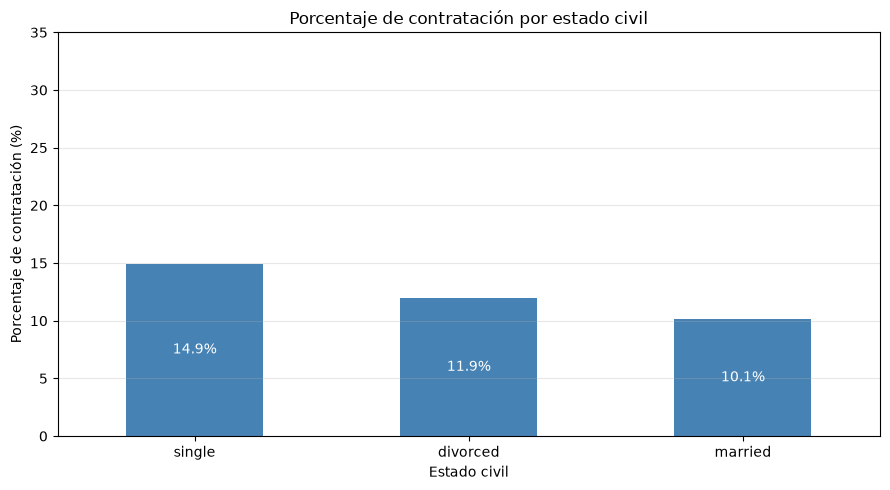

In [44]:
# Calculamos el porcentaje de contratación por estado civil
porcentaje_edo_civil = pd.crosstab(
    df_banco_2['edo_civil'],
    df_banco_2['contrato'],
    normalize='index'
) * 100

# Seleccionamos los clientes que contrataron y ordenamos
tasa_edo_civil = porcentaje_edo_civil['yes'].sort_values(ascending=False)

# Creamos la gráfica
ax = tasa_edo_civil.plot(
    kind='bar',
    figsize=(9, 5),
    title='Porcentaje de contratación por estado civil',
    xlabel='Estado civil',
    ylabel='Porcentaje de contratación (%)',
    color='steelblue'
)

for contenedor in ax.containers:
    ax.bar_label(
        contenedor,
        fmt='%.1f%%',
        label_type='center',
        color='white',
        fontsize=10
    )

plt.xticks(rotation=0)
plt.ylim(0, 35)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

* ¿Qué estado civil presenta mayor porcentaje de contratación?los solteros

* ¿Cuál presenta menor porcentaje? los casados

* ¿Hay diferencias importantes entre los grupos? no se nota mucha diferencia

* Solteros: 14.9%.

* Divorciados: 11.9%.

* Casados: 10.1%.


Aunque existen diferencias entre los grupos, estas son relativamente moderadas. Por lo tanto, el estado civil podría considerarse una variable complementaria para la segmentación de clientes, pero no debería utilizarse como único criterio para definir una campaña de marketing.

#### Número de contactos realizados durante la campaña

In [45]:
# ¿Realizar más llamadas al cliente está relacionado con una mayor contratación?

# Calculamos el porcentaje de contratación por número de contactos
porcentaje_campaign = pd.crosstab(
    df_banco_2['campaña'],
    df_banco_2['contrato'],
    normalize='index'
) * 100

#print(porcentaje_campaign.round(2))

print(porcentaje_campaign.round(2).apply(
    lambda columna: columna.map(lambda x: f'{x:.2f}%')
))

contrato       no     yes
campaña                  
1          85.40%  14.60%
2          88.80%  11.20%
3          88.81%  11.19%
4          91.00%   9.00%
5          92.12%   7.88%
6          92.87%   7.13%
7          93.61%   6.39%
8          94.07%   5.93%
9          93.58%   6.42%
10         94.74%   5.26%
11         92.04%   7.96%
12         97.42%   2.58%
13         95.49%   4.51%
14         95.70%   4.30%
15         95.24%   4.76%
16         97.47%   2.53%
17         91.30%   8.70%
18        100.00%   0.00%
19        100.00%   0.00%
20         97.67%   2.33%
21         97.14%   2.86%
22        100.00%   0.00%
23        100.00%   0.00%
24         95.00%   5.00%
25        100.00%   0.00%
26        100.00%   0.00%
27        100.00%   0.00%
28        100.00%   0.00%
29         93.75%   6.25%
30        100.00%   0.00%
31        100.00%   0.00%
32         88.89%  11.11%
33        100.00%   0.00%
34        100.00%   0.00%
35        100.00%   0.00%
36        100.00%   0.00%
37        10

In [46]:
#estos  son los valores
tabla_campaign = pd.crosstab(
    df_banco_2['campaña'],
    df_banco_2['contrato']
)

print(tabla_campaign)

contrato     no   yes
campaña              
1         14983  2561
2         11104  1401
3          4903   618
4          3205   317
5          1625   139
6          1199    92
7           688    47
8           508    32
9           306    21
10          252    14
11          185    16
12          151     4
13          127     6
14           89     4
15           80     4
16           77     2
17           63     6
18           51     0
19           44     0
20           42     1
21           34     1
22           23     0
23           22     0
24           19     1
25           22     0
26           13     0
27           10     0
28           16     0
29           15     1
30            8     0
31           12     0
32            8     1
33            6     0
34            5     0
35            4     0
36            4     0
37            2     0
38            3     0
39            1     0
41            2     0
43            3     0
44            1     0
46            1     0
50        

In [47]:
df_banco_2['grupo_contactos'] = pd.cut(
    df_banco_2['campaña'],
    bins=[0, 1, 3, 5, 10, float('inf')],
    labels=['1 contacto', '2-3 contactos',
            '4-5 contactos', '6-10 contactos',
            '11 o más contactos']
)

porcentaje_contactos = pd.crosstab(
    df_banco_2['grupo_contactos'],
    df_banco_2['contrato'],
    normalize='index'
) * 100

#print(porcentaje_contactos.round(2))

print(porcentaje_contactos.round(2).apply(
    lambda columna: columna.map(lambda x: f'{x:.2f}%')
))

contrato                no     yes
grupo_contactos                   
1 contacto          85.40%  14.60%
2-3 contactos       88.80%  11.20%
4-5 contactos       91.37%   8.63%
6-10 contactos      93.48%   6.52%
11 o más contactos  96.07%   3.93%


* Los clientes contactados una sola vez presentan el mayor porcentaje de contratación.

* Conforme aumenta el número de contactos, disminuye el porcentaje de contratación.

* Los clientes que recibieron 11 o más contactos presentan la menor tasa de contratación: 3.93%.

#### Clientes por grupo

In [48]:
tabla_grupos = pd.crosstab(
    df_banco_2['grupo_contactos'],
    df_banco_2['contrato']
)

tabla_grupos['total_clientes'] = tabla_grupos.sum(axis=1)

print(tabla_grupos)

contrato               no   yes  total_clientes
grupo_contactos                                
1 contacto          14983  2561           17544
2-3 contactos       16007  2019           18026
4-5 contactos        4830   456            5286
6-10 contactos       2953   206            3159
11 o más contactos   1149    47            1196


In [49]:
tabla_grupos['porcentaje_total'] = (
    tabla_grupos['total_clientes'] /
    tabla_grupos['total_clientes'].sum()
) * 100

#print(tabla_grupos.round(2))
'''
print(tabla_grupos.round(2).apply(
    lambda columna: columna.map(lambda x: f'{x:.2f}%')
))
'''

tabla_formato = tabla_grupos.round(2).copy()

tabla_formato['porcentaje_total'] = tabla_formato['porcentaje_total'].map(
    lambda x: f'{x:.2f}%'
)

print(tabla_formato)

contrato               no   yes  total_clientes porcentaje_total
grupo_contactos                                                 
1 contacto          14983  2561           17544           38.80%
2-3 contactos       16007  2019           18026           39.87%
4-5 contactos        4830   456            5286           11.69%
6-10 contactos       2953   206            3159            6.99%
11 o más contactos   1149    47            1196            2.65%


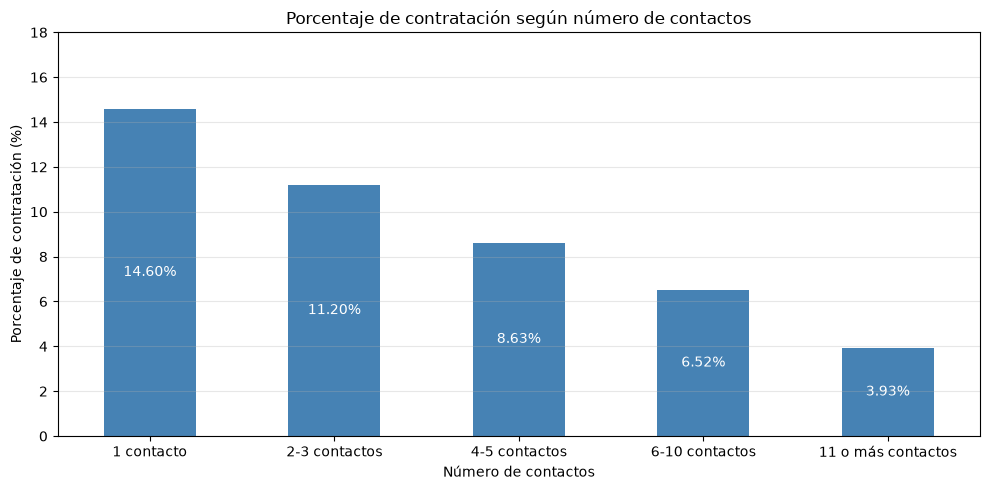

In [50]:
tasa_contactos = porcentaje_contactos['yes']

ax = tasa_contactos.plot(
    kind='bar',
    figsize=(10, 5),
    title='Porcentaje de contratación según número de contactos',
    xlabel='Número de contactos',
    ylabel='Porcentaje de contratación (%)',
    color='steelblue'
)

for contenedor in ax.containers:
    ax.bar_label(
        contenedor,
        fmt='%.2f%%',
        label_type='center',
        color='white',
        fontsize=10
    )

plt.xticks(rotation=0)
plt.ylim(0, 18)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### Análisis de contratación según el número de contactos

Se observa una tendencia decreciente en el porcentaje de contratación conforme aumenta el número de contactos realizados durante la campaña.

Los clientes que recibieron un solo contacto presentan la mayor tasa de contratación, con un 14.60%, mientras que aquellos que recibieron 11 o más contactos registran una tasa del 3.93%.

Este comportamiento sugiere que realizar contactos repetidamente no garantiza mejores resultados. Por ello, se recomienda evaluar la frecuencia de contacto y establecer estrategias de seguimiento más eficientes.

Es importante señalar que los resultados muestran una asociación entre el número de contactos y la contratación, pero no demuestran una relación de causa y efecto.

In [51]:
# Total de clientes analizados
total_clientes = len(df_banco_2)

# Cantidad de clientes que contrataron y no contrataron
contratacion = df_banco_2['contrato'].value_counts()

# Porcentaje de contratación
porcentaje_general = (
    df_banco_2['contrato'].value_counts(normalize=True) * 100
)

print('Total de clientes:', total_clientes)

print('\nCantidad de clientes por contratación:')
print(contratacion)

print('\nPorcentaje de contratación:')
print(porcentaje_general.round(2))

Total de clientes: 45211

Cantidad de clientes por contratación:
contrato
no     39922
yes     5289
Name: count, dtype: int64

Porcentaje de contratación:
contrato
no     88.3
yes    11.7
Name: proportion, dtype: float64


## Conclusiones generales

A partir del análisis de los 45,211 registros de clientes, se identificó que 5,289 aceptaron la oferta bancaria, lo que representa una tasa de contratación del 11.7%. Por otro lado, el 88.3% de los clientes no aceptó la oferta.

Al analizar las características de los clientes, se identificaron los siguientes hallazgos:

- **Edad:** los clientes de 66 años o más presentaron el mayor porcentaje de contratación, con un 42.61%.
- **Ocupación:** los estudiantes registraron la mayor tasa de aceptación, con un 28.68%, seguidos por los clientes retirados, con un 22.79%.
- **Estado civil:** los clientes solteros mostraron el mayor porcentaje de contratación, con un 14.9%, aunque las diferencias entre los grupos fueron moderadas.
- **Número de contactos:** se observó una disminución progresiva en la tasa de contratación conforme aumentó el número de contactos realizados durante la campaña. El grupo que recibió un contacto presentó una tasa del 14.60%, mientras que el grupo de 11 o más contactos registró un 3.93%.

En conjunto, los resultados muestran que existen diferencias en la aceptación de la campaña según las características de los clientes y la frecuencia de contacto.

## Recomendaciones de negocio

1. **Mejorar la segmentación de clientes:** considerar las características de los grupos que mostraron mayores tasas de contratación, como clientes de 66 años o más, estudiantes y personas retiradas.

2. **Optimizar la frecuencia de contacto:** evaluar el número de llamadas realizadas a cada cliente para evitar contactos excesivos que no necesariamente generan mejores resultados.

3. **Diseñar campañas diferenciadas:** desarrollar estrategias de comunicación adaptadas a las características y necesidades de cada segmento.

4. **Monitorear los resultados:** dar seguimiento a indicadores como la tasa de contratación, el número de contactos y la aceptación por segmento para evaluar el desempeño de futuras campañas.